In [ ]:
# ============================================================
# 01c_occupancy_eda.ipynb — 환경 설정 (config.py 자동 로드)
# ============================================================
import sys
import matplotlib.patches as mpatches
from pathlib import Path
from scipy import stats

# 프로젝트 루트를 sys.path에 추가 (실행 위치 무관)
for _p in [Path.cwd(), Path.cwd().parent]:
    if (_p / 'config.py').exists():
        sys.path.insert(0, str(_p))
        break

from config import *  # 모든 상수·경로·KPI·시각화 설정·헬퍼 함수 일괄 적용

# 점유율 EDA용 추가 상수
KPI_OCC_ACTIVE_MEDIAN = 0.512   # Active+Operating TTM 점유율 중위값

# ── 데이터 로드
df    = load_raw()
df_ao = load_raw(active_only=True)

print(f'✅ 데이터 로드: {len(df):,}건 (Active+Oper: {len(df_ao):,}건)')
print(f'\n📋 이 노트북의 분석 범위 (점유율 전용):')
print('  1. 점유율 분포 기초 분석')
print('  2. ADR-점유율 무상관 현상 (가격 탄력성)')
print('  3. RevPAR 분산 분해 (점유율 vs ADR 기여도)')
print('  4. 점유율 모멘텀 (TTM vs L90D)')
print('  5. 리뷰수 → 점유율 직접 경로')
print('  6. 평점 비선형 효과 (Perfectionism Paradox)')
print('  7. 최소숙박일 최적점 분리')
print('  8. 자치구별 점유율 패턴')
print('  9. 고점유 vs 저점유 호스트 프로필')

## 1️⃣ 점유율 분포 기초 분석

**기존 분석과의 차이:** 00/01/01b 노트북은 RevPAR를 주 지표로 두고 점유율을 보조 지표로만 활용했습니다. 
여기서는 점유율 자체를 분석 대상으로 삼아 분포 형태·편향 구조·구간별 특성을 독립적으로 파악합니다.

**핵심 질문:** 점유율이 낮은 숙소들은 왜 낮은가? 구조적 이분성(bimodality)이 있는가?

=== TTM 점유율 기술통계 (Active+Operating, n=14,399) ===
count    14399.0000
mean         0.4938
std          0.2468
min          0.0030
25%          0.2960
50%          0.5120
75%          0.6930
max          0.9950
왜도(Skewness): -0.1423
첨도(Kurtosis): -0.9862


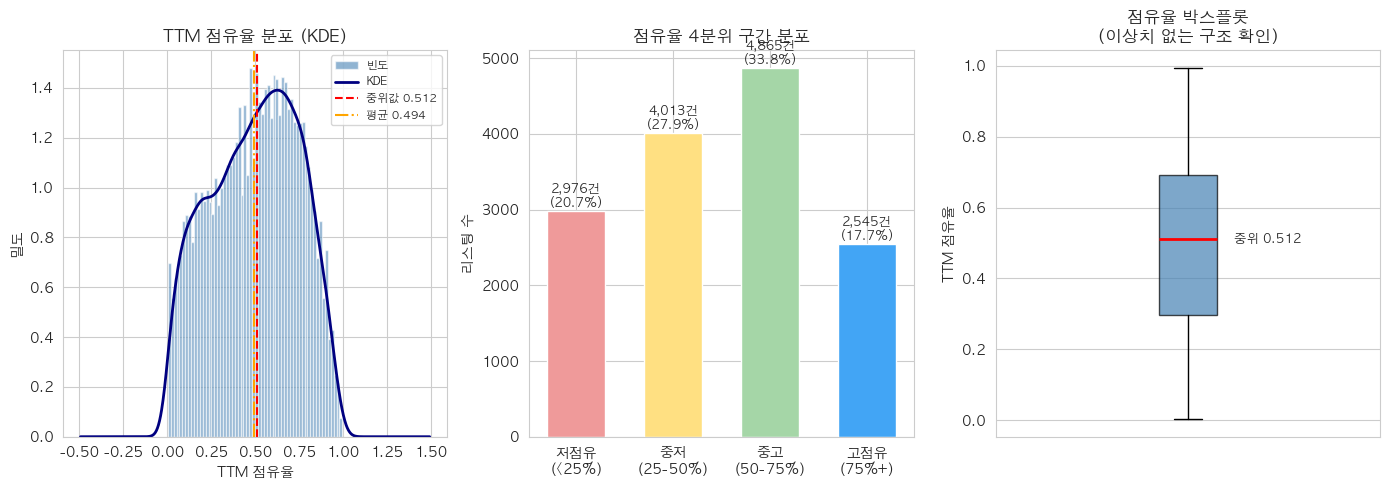


📌 점유율 구간별 RevPAR 중위값:
  저점유
(<25%): ₩12,829
  중저
(25-50%): ₩37,806
  중고
(50-75%): ₩63,978
  고점유
(75%+): ₩89,427


In [3]:
# 점유율 기술통계 및 분포 형태 분석
occ = df_ao['ttm_occupancy']

print('=== TTM 점유율 기술통계 (Active+Operating, n=14,399) ===')
print(occ.describe().apply(lambda x: f'{x:.4f}').to_string())
print(f'왜도(Skewness): {occ.skew():.4f}')
print(f'첨도(Kurtosis): {occ.kurtosis():.4f}')

# 4분위 구간 분포
occ_tiers = pd.cut(occ, bins=[0, 0.25, 0.50, 0.75, 1.0],
                   labels=['저점유\n(<25%)', '중저\n(25-50%)', '중고\n(50-75%)', '고점유\n(75%+)'],
                   include_lowest=True)
tier_counts = occ_tiers.value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# 히스토그램 + KDE
axes[0].hist(occ, bins=60, density=True, color='steelblue', alpha=0.6, edgecolor='white', label='빈도')
occ.plot.kde(ax=axes[0], color='navy', linewidth=2, label='KDE')
axes[0].axvline(occ.median(), color='red', linestyle='--', linewidth=1.5, label=f'중위값 {occ.median():.3f}')
axes[0].axvline(occ.mean(), color='orange', linestyle='-.', linewidth=1.5, label=f'평균 {occ.mean():.3f}')
axes[0].set_title('TTM 점유율 분포 (KDE)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('TTM 점유율')
axes[0].set_ylabel('밀도')
axes[0].legend(fontsize=8)

# 4분위 구간 막대
colors_tier = ['#EF9A9A', '#FFE082', '#A5D6A7', '#42A5F5']
bars = axes[1].bar(tier_counts.index, tier_counts.values, color=colors_tier, edgecolor='white', width=0.6)
axes[1].set_title('점유율 4분위 구간 분포', fontsize=12, fontweight='bold')
axes[1].set_ylabel('리스팅 수')
for bar, cnt in zip(bars, tier_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{cnt:,}건\n({cnt/len(occ)*100:.1f}%)',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# 박스플롯 (이상치 가시화)
bp = axes[2].boxplot(occ, vert=True, patch_artist=True,
                     boxprops=dict(facecolor='steelblue', alpha=0.7),
                     medianprops=dict(color='red', linewidth=2),
                     flierprops=dict(marker='.', markersize=2, alpha=0.3))
axes[2].set_title('점유율 박스플롯\n(이상치 없는 구조 확인)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('TTM 점유율')
axes[2].set_xticks([])
axes[2].text(1.12, occ.median(), f'중위 {occ.median():.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_1_occ_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

print(f'\n📌 점유율 구간별 RevPAR 중위값:')
df_ao['occ_tier'] = occ_tiers
tier_revpar = df_ao.groupby('occ_tier', observed=True)['ttm_revpar'].median()
for tier, val in tier_revpar.items():
    print(f'  {tier}: ₩{val:,.0f}')


## 2️⃣ ADR-점유율 무상관 현상 — 가격 탄력성 관점

**기존 분석과의 차이:** 01b-A에서 ADR×점유율 4분면을 분석했으나, "가격이 점유율에 영향을 주는가?"라는 탄력성 질문을 직접 검증하지 않았습니다.

**핵심 발견:** ADR-점유율 Pearson r = **0.009** (사실상 무상관). 이는 
- 가격을 올려도 점유율이 떨어지지 않는다는 의미
- RevPAR 차이가 ADR이 아닌 **점유율 차이**에서 주로 발생한다는 의미

**전략적 시사점:** 가격 인하로 점유율을 높이는 전략은 서울 에어비앤비 시장에서 비효율적일 수 있습니다.

=== ADR ↔ 점유율 상관관계 ===
  Pearson  r = 0.0095  (p = 0.2567)
  Spearman r = 0.0487  (p = 0.0000)

📌 해석: r ≈ 0 → 가격과 점유율은 통계적으로 독립적


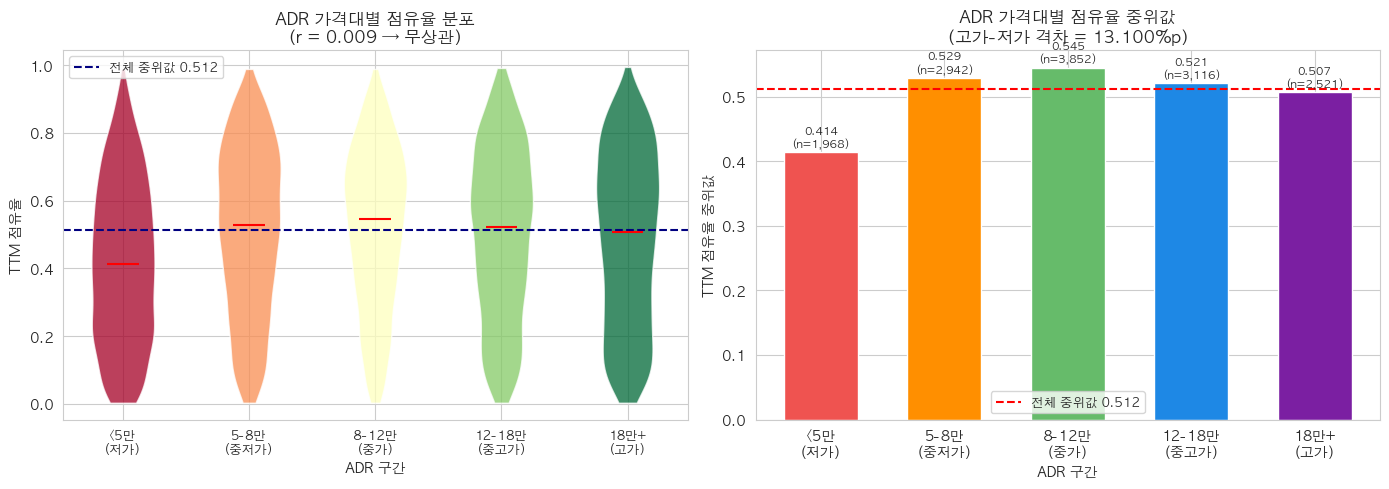


=== ADR 구간별 점유율 통계 ===
               median   mean  count
adr_grp                            
<5만\n(저가)       0.414  0.420   1968
5-8만\n(중저가)     0.529  0.510   2942
8-12만\n(중가)     0.545  0.518   3852
12-18만\n(중고가)   0.521  0.500   3116
18만+\n(고가)      0.507  0.487   2521

⚠️ 저가(<5만)와 고가(18만+) 점유율 중위값 차이: 9.3%p


In [4]:
# 가격 탄력성 검증: ADR vs 점유율
corr_pearson, p_pearson = stats.pearsonr(df_ao['ttm_avg_rate'], df_ao['ttm_occupancy'])
corr_spearman, p_spearman = stats.spearmanr(df_ao['ttm_avg_rate'], df_ao['ttm_occupancy'])

print('=== ADR ↔ 점유율 상관관계 ===')
print(f'  Pearson  r = {corr_pearson:.4f}  (p = {p_pearson:.4f})')
print(f'  Spearman r = {corr_spearman:.4f}  (p = {p_spearman:.4f})')
print(f'\n📌 해석: r ≈ 0 → 가격과 점유율은 통계적으로 독립적')

# ADR 구간별 점유율 분포 (핵심 시각화)
bins_adr = [0, 50000, 80000, 120000, 180000, 2000000]
labels_adr = ['<5만\n(저가)', '5-8만\n(중저가)', '8-12만\n(중가)', '12-18만\n(중고가)', '18만+\n(고가)']
df_ao['adr_grp'] = pd.cut(df_ao['ttm_avg_rate'], bins=bins_adr, labels=labels_adr)

occ_by_adr = df_ao.groupby('adr_grp', observed=True)['ttm_occupancy'].agg(['median', 'mean', 'count']).round(3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 바이올린 플롯: ADR 구간별 점유율 분포
grp_order = [str(l) for l in labels_adr]
df_violin = df_ao.dropna(subset=['adr_grp'])
groups = [df_violin[df_violin['adr_grp'] == g]['ttm_occupancy'].values for g in df_violin['adr_grp'].cat.categories]
vp = axes[0].violinplot(groups, positions=range(len(groups)), showmedians=True, showextrema=False)
for i, body in enumerate(vp['bodies']):
    body.set_facecolor(plt.cm.RdYlGn(i / (len(groups) - 1)))
    body.set_alpha(0.75)
vp['cmedians'].set_color('red')
axes[0].set_xticks(range(len(labels_adr)))
axes[0].set_xticklabels(labels_adr, fontsize=9)
axes[0].axhline(KPI_OCC_ACTIVE_MEDIAN, color='navy', linestyle='--', linewidth=1.5,
                label=f'전체 중위값 {KPI_OCC_ACTIVE_MEDIAN:.3f}')
axes[0].set_title('ADR 가격대별 점유율 분포\n(r = {:.3f} → 무상관)'.format(corr_pearson),
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('ADR 구간')
axes[0].set_ylabel('TTM 점유율')
axes[0].legend(fontsize=9)

# 구간별 점유율 중위값 막대
colors_adr = ['#EF5350', '#FF8F00', '#66BB6A', '#1E88E5', '#7B1FA2']
bars = axes[1].bar(occ_by_adr.index.astype(str), occ_by_adr['median'],
                   color=colors_adr[:len(occ_by_adr)], width=0.6, edgecolor='white')
axes[1].axhline(KPI_OCC_ACTIVE_MEDIAN, color='red', linestyle='--',
                label=f'전체 중위값 {KPI_OCC_ACTIVE_MEDIAN:.3f}')
axes[1].set_title('ADR 가격대별 점유율 중위값\n(고가-저가 격차 = {:.3f}%p)'.format(
                  (occ_by_adr['median'].max() - occ_by_adr['median'].min()) * 100),
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('ADR 구간')
axes[1].set_ylabel('TTM 점유율 중위값')
for bar, (_, row) in zip(bars, occ_by_adr.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{row["median"]:.3f}\n(n={int(row["count"]):,})',
                 ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_2_adr_occ_independence.png', dpi=100, bbox_inches='tight')
plt.show()

print('\n=== ADR 구간별 점유율 통계 ===')
print(occ_by_adr.to_string())
print(f'\n⚠️ 저가(<5만)와 고가(18만+) 점유율 중위값 차이: '
      f'{abs(occ_by_adr["median"].iloc[0] - occ_by_adr["median"].iloc[-1])*100:.1f}%p')


## 3️⃣ RevPAR 분산 분해 — 점유율 vs ADR의 기여도

**기존 분석과의 차이:** 01b-A에서 4분면 분류로 '고가-고점유' 조합이 최고 RevPAR임을 확인했습니다. 
여기서는 한 발 더 나아가, **RevPAR 전체 분산 중 점유율 분산이 ADR 분산보다 더 크게 기여하는지**를 정량적으로 검증합니다.

**방법:** log(RevPAR) = log(ADR) + log(점유율) 분해 후 각 성분의 분산 기여도 계산

=== log(RevPAR) 분산 분해 ===
  Var(log RevPAR)    = 1.1449  (100.0%)
  Var(log ADR)       = 0.4290  (37.5%)
  Var(log 점유율)     = 0.6660  (58.2%)
  2×Cov(ADR,점유율)  = 0.0519  (4.5%)

📌 점유율 기여도(58.2%) vs ADR 기여도(37.5%)


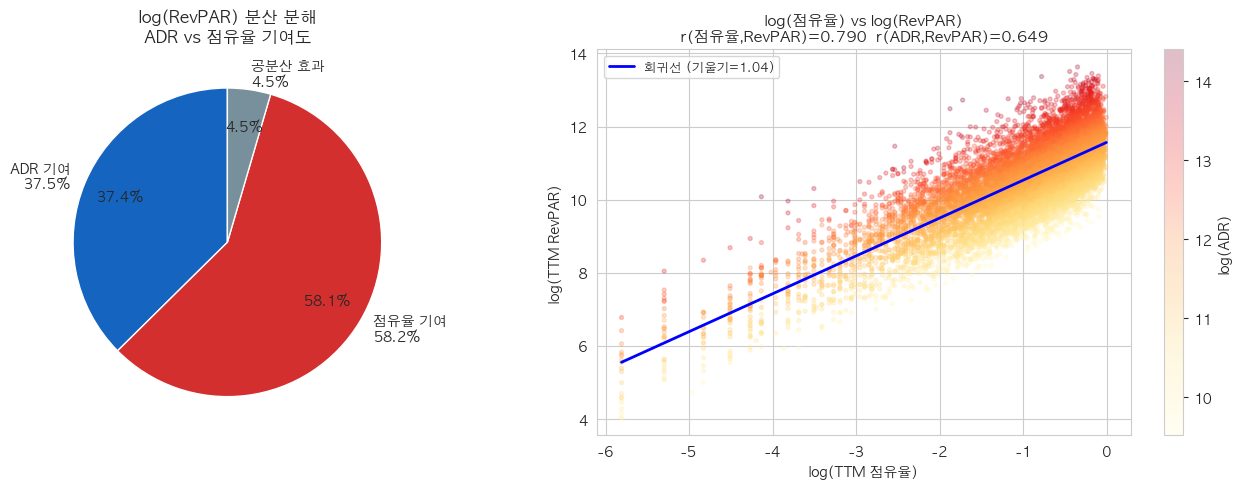

In [5]:
# RevPAR 분산 분해: RevPAR = ADR × 점유율 → log 변환 후 분산 분해
df_decomp = df_ao[(df_ao['ttm_revpar'] > 0) & (df_ao['ttm_occupancy'] > 0) &
                  (df_ao['ttm_avg_rate'] > 0)].copy()

df_decomp['log_revpar'] = np.log(df_decomp['ttm_revpar'])
df_decomp['log_adr'] = np.log(df_decomp['ttm_avg_rate'])
df_decomp['log_occ'] = np.log(df_decomp['ttm_occupancy'])

var_revpar = df_decomp['log_revpar'].var()
var_adr = df_decomp['log_adr'].var()
var_occ = df_decomp['log_occ'].var()
cov_adr_occ = df_decomp[['log_adr', 'log_occ']].cov().iloc[0, 1]

# Var(log_revpar) = Var(log_adr) + Var(log_occ) + 2*Cov(log_adr, log_occ)
contrib_adr = var_adr / var_revpar * 100
contrib_occ = var_occ / var_revpar * 100
contrib_cov = 2 * cov_adr_occ / var_revpar * 100

print('=== log(RevPAR) 분산 분해 ===')
print(f'  Var(log RevPAR)    = {var_revpar:.4f}  (100.0%)')
print(f'  Var(log ADR)       = {var_adr:.4f}  ({contrib_adr:.1f}%)')
print(f'  Var(log 점유율)     = {var_occ:.4f}  ({contrib_occ:.1f}%)')
print(f'  2×Cov(ADR,점유율)  = {2*cov_adr_occ:.4f}  ({contrib_cov:.1f}%)')
print(f'\n📌 점유율 기여도({contrib_occ:.1f}%) vs ADR 기여도({contrib_adr:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 파이차트: 분산 분해
pie_vals = [max(contrib_adr, 0), max(contrib_occ, 0), max(contrib_cov, 0)]
pie_labels = [f'ADR 기여\n{contrib_adr:.1f}%', f'점유율 기여\n{contrib_occ:.1f}%',
              f'공분산 효과\n{contrib_cov:.1f}%']
pie_colors = ['#1565C0', '#D32F2F', '#78909C']
axes[0].pie(pie_vals, labels=pie_labels, colors=pie_colors,
            autopct='%1.1f%%', startangle=90, pctdistance=0.75)
axes[0].set_title('log(RevPAR) 분산 분해\nADR vs 점유율 기여도', fontsize=12, fontweight='bold')

# 산점도: log_occ vs log_revpar (ADR 색상)
sc = axes[1].scatter(df_decomp['log_occ'], df_decomp['log_revpar'],
                     c=df_decomp['log_adr'], cmap='YlOrRd',
                     alpha=0.25, s=8)
# 회귀선 (점유율 → RevPAR)
z = np.polyfit(df_decomp['log_occ'], df_decomp['log_revpar'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_decomp['log_occ'].min(), df_decomp['log_occ'].max(), 100)
axes[1].plot(x_line, p(x_line), 'b-', linewidth=2,
             label=f'회귀선 (기울기={z[0]:.2f})')
plt.colorbar(sc, ax=axes[1], label='log(ADR)')
r_occ_rev = np.corrcoef(df_decomp['log_occ'], df_decomp['log_revpar'])[0, 1]
r_adr_rev = np.corrcoef(df_decomp['log_adr'], df_decomp['log_revpar'])[0, 1]
axes[1].set_title(f'log(점유율) vs log(RevPAR)\n'
                  f'r(점유율,RevPAR)={r_occ_rev:.3f}  r(ADR,RevPAR)={r_adr_rev:.3f}',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('log(TTM 점유율)')
axes[1].set_ylabel('log(TTM RevPAR)')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_3_revpar_decomposition.png', dpi=100, bbox_inches='tight')
plt.show()


## 4️⃣ 점유율 모멘텀 — TTM vs L90D 변화 방향

**기존 분석과의 차이:** 01b-E에서 RevPAR 트렌드(`l90d_revpar vs ttm_revpar/4`)를 분석했습니다. 
여기서는 **점유율 자체의 최근 방향**(`l90d_occupancy vs ttm_occupancy`)을 분석합니다.

**핵심 질문:** 점유율이 하락 추세인 숙소들의 공통 특성은 무엇인가? 어떤 호스트들이 점유율 모멘텀을 유지하고 있는가?

=== 점유율 모멘텀 분류 (L90D - TTM) ===
  급락 (-15%p↓): 3,324건 (23.1%)
  하락 (-15~-3%p): 3,516건 (24.4%)
  보합 (±3%p): 2,398건 (16.7%)
  상승 (+3~+15%p): 3,047건 (21.2%)
  급등 (+15%p↑): 2,114건 (14.7%)


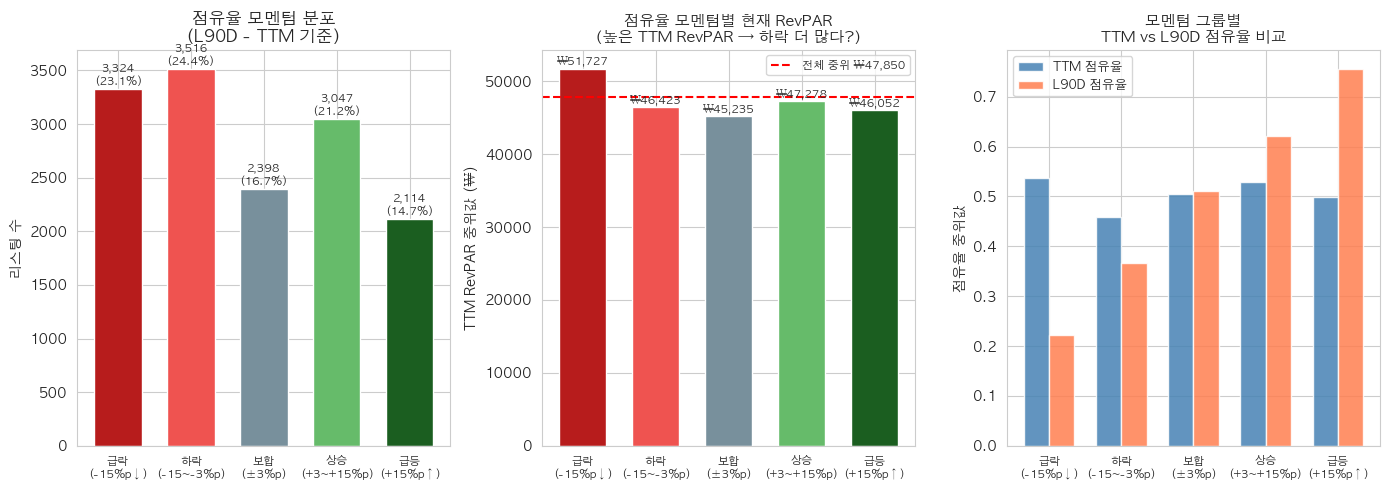


=== 점유율 모멘텀별 호스트 특성 ===
                슈퍼호스트율  즉시예약율  중위_사진수  중위_리뷰수
occ_momentum                                 
급락\n(-15%p↓)      53.9   39.6    26.0    39.0
하락\n(-15~-3%p)    51.9   41.5    26.0    38.0
보합\n(±3%p)        54.5   42.5    26.0    39.0
상승\n(+3~+15%p)    58.9   42.5    27.0    34.0
급등\n(+15%p↑)      66.7   39.8    29.0    28.0


In [6]:
# 점유율 모멘텀: L90D - TTM 차이
df_ao['occ_delta'] = df_ao['l90d_occupancy'] - df_ao['ttm_occupancy']

# 5분류 모멘텀
df_ao['occ_momentum'] = pd.cut(
    df_ao['occ_delta'],
    bins=[-1.0, -0.15, -0.03, 0.03, 0.15, 1.0],
    labels=['급락\n(-15%p↓)', '하락\n(-15~-3%p)', '보합\n(±3%p)', '상승\n(+3~+15%p)', '급등\n(+15%p↑)']
)

mom_counts = df_ao['occ_momentum'].value_counts().sort_index()

print('=== 점유율 모멘텀 분류 (L90D - TTM) ===')
for cat, cnt in mom_counts.items():
    print(f'  {cat.replace(chr(10)," ")}: {cnt:,}건 ({cnt/len(df_ao)*100:.1f}%)')

# 모멘텀별 TTM RevPAR (점유율 모멘텀이 현재 RevPAR 수준과 관계 있는지)
mom_revpar = df_ao.groupby('occ_momentum', observed=True)['ttm_revpar'].median()
mom_ttm_occ = df_ao.groupby('occ_momentum', observed=True)['ttm_occupancy'].median()
mom_l90_occ = df_ao.groupby('occ_momentum', observed=True)['l90d_occupancy'].median()

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# 모멘텀 구분 막대
colors_mom = ['#B71C1C', '#EF5350', '#78909C', '#66BB6A', '#1B5E20']
bars = axes[0].bar(mom_counts.index.astype(str), mom_counts.values,
                   color=colors_mom, width=0.65, edgecolor='white')
axes[0].set_title('점유율 모멘텀 분포\n(L90D - TTM 기준)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('리스팅 수')
axes[0].tick_params(axis='x', labelsize=8)
for bar, cnt in zip(bars, mom_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{cnt:,}\n({cnt/len(df_ao)*100:.1f}%)',
                 ha='center', va='bottom', fontsize=8)

# 모멘텀별 TTM RevPAR (현재 성과와 모멘텀 관계)
bars2 = axes[1].bar(mom_revpar.index.astype(str), mom_revpar.values,
                    color=colors_mom, width=0.65, edgecolor='white')
axes[1].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--',
                label=f'전체 중위 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,}')
axes[1].set_title('점유율 모멘텀별 현재 RevPAR\n(높은 TTM RevPAR → 하락 더 많다?)',
                  fontsize=11, fontweight='bold')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
axes[1].tick_params(axis='x', labelsize=8)
for bar, val in zip(bars2, mom_revpar.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'₩{val:,.0f}', ha='center', va='bottom', fontsize=8)
axes[1].legend(fontsize=8)

# TTM vs L90D 점유율 비교 (모멘텀별)
x = np.arange(len(mom_ttm_occ))
w = 0.35
axes[2].bar(x - w/2, mom_ttm_occ.values, w, label='TTM 점유율', color='steelblue', alpha=0.85)
axes[2].bar(x + w/2, mom_l90_occ.values, w, label='L90D 점유율', color='coral', alpha=0.85)
axes[2].set_xticks(x)
axes[2].set_xticklabels(mom_ttm_occ.index.astype(str), fontsize=8)
axes[2].set_title('모멘텀 그룹별\nTTM vs L90D 점유율 비교', fontsize=11, fontweight='bold')
axes[2].set_ylabel('점유율 중위값')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_4_occ_momentum.png', dpi=100, bbox_inches='tight')
plt.show()

# 모멘텀별 호스트 특성
mom_profile = df_ao.groupby('occ_momentum', observed=True).agg(
    슈퍼호스트율=('superhost', lambda x: x.mean() * 100),
    즉시예약율=('instant_book', lambda x: x.mean() * 100),
    중위_사진수=('photos_count', 'median'),
    중위_리뷰수=('num_reviews', 'median')
).round(1)
print('\n=== 점유율 모멘텀별 호스트 특성 ===')
print(mom_profile.to_string())


## 5️⃣ 리뷰수 → 점유율 직접 경로

**기존 분석과의 차이:** 01b-B에서 리뷰수 → RevPAR 관계를 분석했습니다. 
RevPAR = ADR × 점유율이므로 리뷰수가 RevPAR에 영향을 미칠 때, 그것이 **ADR 경로**인지 **점유율 경로**인지 구분되지 않았습니다.

여기서는 리뷰수와 **점유율만의 관계**를 직접 분석합니다.

=== 리뷰수와 점유율/ADR 상관관계 (Spearman) ===
  리뷰수 ↔ 점유율:  r = 0.6087  (p = 0.00e+00)
  리뷰수 ↔ ADR:     r = 0.1564  (p = 1.75e-79)

📌 리뷰수는 ADR보다 점유율과 더 강하게 연관됨


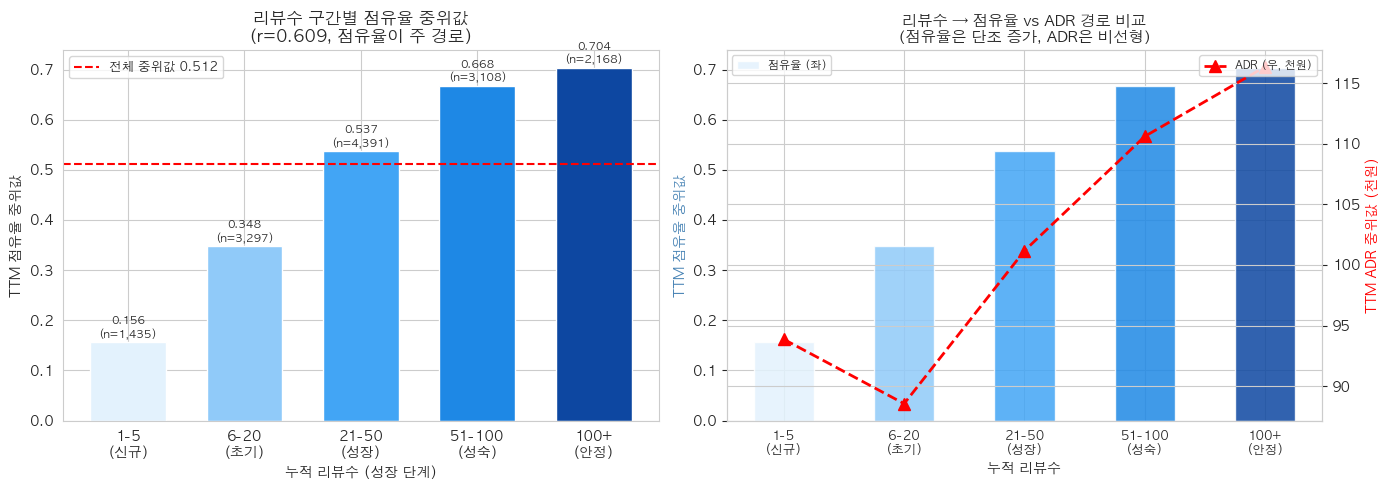


=== 리뷰수 구간별 점유율 / ADR / RevPAR ===
              점유율 중위 ADR 중위(₩) RevPAR 중위(₩)  리스팅수
rev_grp                                          
1-5\n(신규)      0.156   ₩93,861      ₩14,232  1435
6-20\n(초기)     0.348   ₩88,545      ₩27,812  3297
21-50\n(성장)    0.537  ₩101,171      ₩50,863  4391
51-100\n(성숙)   0.668  ₩110,619      ₩69,252  3108
100+\n(안정)     0.704  ₩116,369      ₩76,152  2168


In [7]:
# 리뷰수 → 점유율 직접 관계
r_rev_occ, p_rev_occ = stats.spearmanr(df_ao['num_reviews'], df_ao['ttm_occupancy'])
r_rev_adr, p_rev_adr = stats.spearmanr(df_ao['num_reviews'], df_ao['ttm_avg_rate'])

print('=== 리뷰수와 점유율/ADR 상관관계 (Spearman) ===')
print(f'  리뷰수 ↔ 점유율:  r = {r_rev_occ:.4f}  (p = {p_rev_occ:.2e})')
print(f'  리뷰수 ↔ ADR:     r = {r_rev_adr:.4f}  (p = {p_rev_adr:.2e})')
print(f'\n📌 리뷰수는 ADR보다 점유율과 더 강하게 연관됨')

# 리뷰수 구간별 점유율 vs ADR (비교)
bins_rev = [0, 5, 20, 50, 100, 9999]
labels_rev = ['1-5\n(신규)', '6-20\n(초기)', '21-50\n(성장)', '51-100\n(성숙)', '100+\n(안정)']
df_ao['rev_grp'] = pd.cut(df_ao['num_reviews'], bins=bins_rev, labels=labels_rev)

rev_occ = df_ao.groupby('rev_grp', observed=True)['ttm_occupancy'].agg(['median', 'count'])
rev_adr = df_ao.groupby('rev_grp', observed=True)['ttm_avg_rate'].median()
rev_revpar = df_ao.groupby('rev_grp', observed=True)['ttm_revpar'].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 점유율 단독 경로
colors_rev = ['#E3F2FD', '#90CAF9', '#42A5F5', '#1E88E5', '#0D47A1']
bars = axes[0].bar(rev_occ.index.astype(str), rev_occ['median'],
                   color=colors_rev, width=0.65, edgecolor='white')
axes[0].axhline(KPI_OCC_ACTIVE_MEDIAN, color='red', linestyle='--',
                label=f'전체 중위값 {KPI_OCC_ACTIVE_MEDIAN:.3f}')
axes[0].set_title('리뷰수 구간별 점유율 중위값\n(r={:.3f}, 점유율이 주 경로)'.format(r_rev_occ),
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('누적 리뷰수 (성장 단계)')
axes[0].set_ylabel('TTM 점유율 중위값')
for bar, (_, row) in zip(bars, rev_occ.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{row["median"]:.3f}\n(n={int(row["count"]):,})',
                 ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[0].legend(fontsize=9)

# 점유율 vs ADR 동시 비교 (리뷰수 경로 분해)
x = np.arange(len(rev_occ))
ax2 = axes[1].twinx()
axes[1].bar(x, rev_occ['median'], color=colors_rev, width=0.5, alpha=0.85, label='점유율 (좌)')
ax2.plot(x, rev_adr / 1000, 'r^--', markersize=8, linewidth=2, label='ADR (우, 천원)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(rev_occ.index.astype(str), fontsize=9)
axes[1].set_title('리뷰수 → 점유율 vs ADR 경로 비교\n(점유율은 단조 증가, ADR은 비선형)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('누적 리뷰수')
axes[1].set_ylabel('TTM 점유율 중위값', color='steelblue')
ax2.set_ylabel('TTM ADR 중위값 (천원)', color='red')
axes[1].legend(loc='upper left', fontsize=8)
ax2.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_5_reviews_occ_path.png', dpi=100, bbox_inches='tight')
plt.show()

print('\n=== 리뷰수 구간별 점유율 / ADR / RevPAR ===')
summary_rev = pd.DataFrame({
    '점유율 중위': rev_occ['median'],
    'ADR 중위(₩)': rev_adr.apply(lambda x: f'₩{x:,.0f}'),
    'RevPAR 중위(₩)': rev_revpar.apply(lambda x: f'₩{x:,.0f}'),
    '리스팅수': rev_occ['count'].astype(int)
})
print(summary_rev.to_string())


## 6️⃣ 평점 비선형 효과 — Perfectionism Paradox

**기존 분석과의 차이:** 01_host_eda H3에서 평점 vs RevPAR 산점도를 분석했으나, 평점 구간별 **점유율 비선형성**은 분석하지 않았습니다.

**핵심 발견:** 평점 4.85-4.95 구간이 점유율 최고 (0.622)이고, 4.95-5.0(완벽 평점) 구간은 오히려 낮습니다 (0.532). 
이는 "완벽한 평점이 최고 점유율을 보장하지 않는다"는 직관에 반하는 결과입니다.

=== 평점 구간별 점유율 (비선형 패턴 확인) ===
            occ_med  occ_mean  revpar_med  count
rating_grp                                      
<4.0          0.195     0.222    13458.50    366
4.0-4.5       0.334     0.359    23150.40   1393
4.5-4.7       0.463     0.462    37828.00   2172
4.7-4.85      0.553     0.533    53436.15   3786
4.85-4.95     0.622     0.591    66586.15   3942
4.95-5.0      0.532     0.511    58205.65   2144

📌 점유율 최고 구간: 4.85-4.95 (0.622)
📌 완벽 평점(4.95-5.0) 점유율: 0.532 (최고 구간보다 낮음)


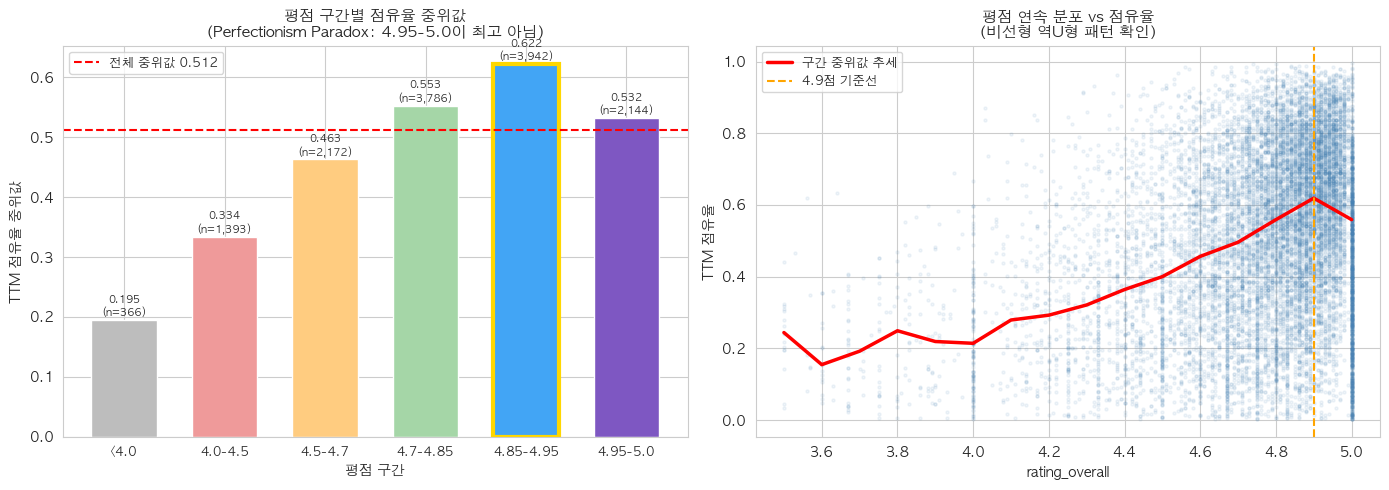

In [8]:
# 평점 비선형 효과 분석
df_rated = df_ao.dropna(subset=['rating_overall']).copy()

# 세밀한 구간 분류
bins_rating = [0, 4.0, 4.5, 4.7, 4.85, 4.95, 5.01]
labels_rating = ['<4.0', '4.0-4.5', '4.5-4.7', '4.7-4.85', '4.85-4.95', '4.95-5.0']
df_rated['rating_grp'] = pd.cut(df_rated['rating_overall'], bins=bins_rating, labels=labels_rating)

rat_stats = df_rated.groupby('rating_grp', observed=True).agg(
    occ_med=('ttm_occupancy', 'median'),
    occ_mean=('ttm_occupancy', 'mean'),
    revpar_med=('ttm_revpar', 'median'),
    adr_med=('ttm_avg_rate', 'median'),
    count=('ttm_occupancy', 'count')
)

print('=== 평점 구간별 점유율 (비선형 패턴 확인) ===')
print(rat_stats[['occ_med', 'occ_mean', 'revpar_med', 'count']].round(3).to_string())

# Perfectionism Paradox 근거: 4.95-5.0이 오히려 하락
peak_idx = rat_stats['occ_med'].idxmax()
print(f'\n📌 점유율 최고 구간: {peak_idx} ({rat_stats.loc[peak_idx, "occ_med"]:.3f})')
top_occ = rat_stats.loc['4.95-5.0', 'occ_med'] if '4.95-5.0' in rat_stats.index else None
if top_occ:
    print(f'📌 완벽 평점(4.95-5.0) 점유율: {top_occ:.3f} (최고 구간보다 낮음)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 평점 구간별 점유율 막대 (비선형 패턴 시각화)
colors_rat = ['#BDBDBD', '#EF9A9A', '#FFCC80', '#A5D6A7', '#42A5F5', '#7E57C2']
bars = axes[0].bar(rat_stats.index.astype(str), rat_stats['occ_med'],
                   color=colors_rat[:len(rat_stats)], width=0.65, edgecolor='white')
axes[0].axhline(KPI_OCC_ACTIVE_MEDIAN, color='red', linestyle='--',
                label=f'전체 중위값 {KPI_OCC_ACTIVE_MEDIAN:.3f}')
# 최고 구간 하이라이트
if peak_idx in rat_stats.index:
    peak_pos = list(rat_stats.index).index(peak_idx)
    bars[peak_pos].set_edgecolor('gold')
    bars[peak_pos].set_linewidth(3)
axes[0].set_title('평점 구간별 점유율 중위값\n(Perfectionism Paradox: 4.95-5.0이 최고 아님)',
                  fontsize=11, fontweight='bold')
axes[0].set_xlabel('평점 구간')
axes[0].set_ylabel('TTM 점유율 중위값')
for bar, (_, row) in zip(bars, rat_stats.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                 f'{row["occ_med"]:.3f}\n(n={int(row["count"]):,})',
                 ha='center', va='bottom', fontsize=7.5)
axes[0].legend(fontsize=9)
axes[0].tick_params(axis='x', labelsize=9)

# 평점 연속 산점도 (점유율 색상)
df_scatter = df_rated[(df_rated['rating_overall'] >= 3.5)]
# 평균 추세 곡선
rat_cont = df_scatter.groupby(df_scatter['rating_overall'].round(1))['ttm_occupancy'].median()
axes[1].scatter(df_scatter['rating_overall'], df_scatter['ttm_occupancy'],
                alpha=0.08, s=5, color='steelblue')
axes[1].plot(rat_cont.index, rat_cont.values, 'r-', linewidth=2.5,
             label='구간 중위값 추세')
axes[1].axvline(4.9, color='orange', linestyle='--', linewidth=1.5, label='4.9점 기준선')
axes[1].set_title('평점 연속 분포 vs 점유율\n(비선형 역U형 패턴 확인)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('rating_overall')
axes[1].set_ylabel('TTM 점유율')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_6_rating_nonlinear.png', dpi=100, bbox_inches='tight')
plt.show()


## 7️⃣ 최소숙박일 최적점 분리 — RevPAR 최적 ≠ 점유율 최적

**기존 분석과의 차이:** 01_host_eda H4에서 최소숙박일 → RevPAR를 분석하여 "2-3박이 최적"이라 결론지었습니다.
그러나 점유율 관점에서는 **4-7박 구간이 가장 높은 점유율**을 보입니다.

**핵심 발견:** 
- RevPAR 최적: 2-3박
- 점유율 최적: 4-7박

이 분리는 호스트의 전략 목표(RevPAR 극대화 vs 점유율 극대화)에 따라 최소숙박일 설정이 달라져야 함을 시사합니다.

=== 최소숙박일별 점유율 / RevPAR ===
        occ_med  revpar_med     adr_med  count
mn_grp                                        
1박        0.488     48739.7  109921.359   5351
2박        0.581     53969.6  103953.877   2440
3박        0.581     58540.6  110496.971   1799
4-7박      0.597     49681.0   92638.619   2132
8-30박     0.422     23745.0   61417.368    844
30박+      0.367     13442.9   46708.270    105

📌 점유율 최적 구간: 4-7박 (점유율 0.597)
📌 RevPAR 최적 구간: 3박 (RevPAR ₩58,541)
⚠️ 두 최적점이 다름 → 전략 목표에 따른 설정 분리 필요


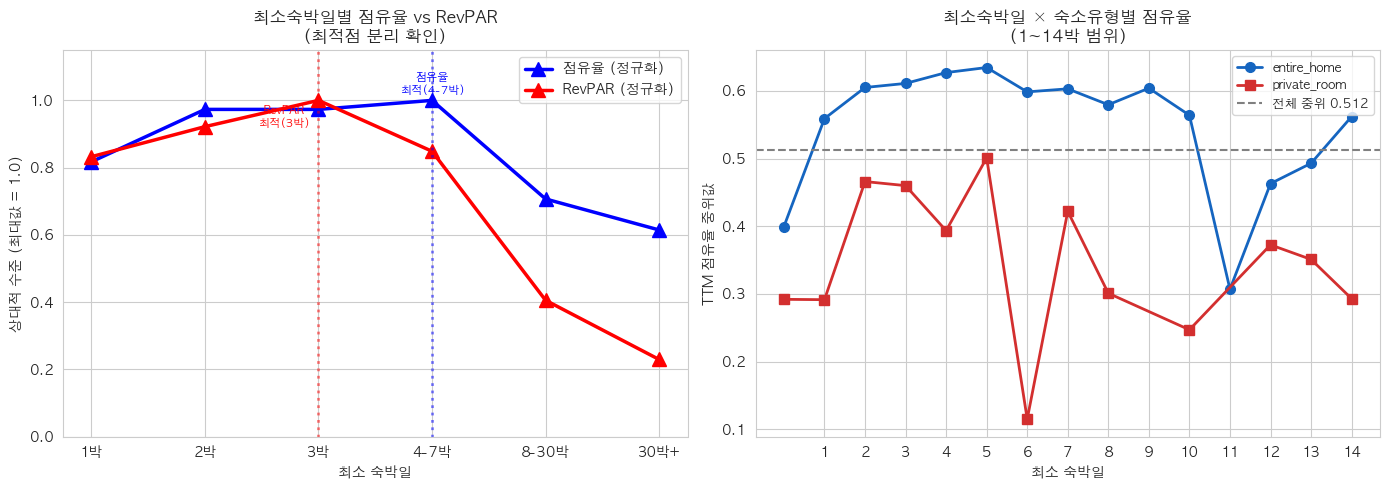

In [9]:
# 최소숙박일 구간별 점유율 vs RevPAR 분리 분석
bins_mn = [0, 1, 2, 3, 7, 30, 9999]
labels_mn = ['1박', '2박', '3박', '4-7박', '8-30박', '30박+']
df_ao['mn_grp'] = pd.cut(df_ao['min_nights'], bins=bins_mn, labels=labels_mn)

mn_stats = df_ao.groupby('mn_grp', observed=True).agg(
    occ_med=('ttm_occupancy', 'median'),
    revpar_med=('ttm_revpar', 'median'),
    adr_med=('ttm_avg_rate', 'median'),
    count=('ttm_occupancy', 'count')
)

occ_optimal = mn_stats['occ_med'].idxmax()
revpar_optimal = mn_stats['revpar_med'].idxmax()

print('=== 최소숙박일별 점유율 / RevPAR ===')
print(mn_stats[['occ_med', 'revpar_med', 'adr_med', 'count']].round(3).to_string())
print(f'\n📌 점유율 최적 구간: {occ_optimal} (점유율 {mn_stats.loc[occ_optimal, "occ_med"]:.3f})')
print(f'📌 RevPAR 최적 구간: {revpar_optimal} (RevPAR ₩{mn_stats.loc[revpar_optimal, "revpar_med"]:,.0f})')
if occ_optimal != revpar_optimal:
    print(f'⚠️ 두 최적점이 다름 → 전략 목표에 따른 설정 분리 필요')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 점유율 vs RevPAR 동시 비교
x = np.arange(len(mn_stats))
w = 0.35
# 정규화하여 동일 축 비교
occ_norm = mn_stats['occ_med'] / mn_stats['occ_med'].max()
revpar_norm = mn_stats['revpar_med'] / mn_stats['revpar_med'].max()

axes[0].plot(x, occ_norm.values, 'b^-', markersize=10, linewidth=2.5, label='점유율 (정규화)')
axes[0].plot(x, revpar_norm.values, 'r^-', markersize=10, linewidth=2.5, label='RevPAR (정규화)')

# 최적점 표시
occ_opt_i = list(mn_stats.index).index(occ_optimal)
revpar_opt_i = list(mn_stats.index).index(revpar_optimal)
axes[0].axvline(occ_opt_i, color='blue', linestyle=':', alpha=0.5, linewidth=2)
axes[0].axvline(revpar_opt_i, color='red', linestyle=':', alpha=0.5, linewidth=2)
axes[0].text(occ_opt_i, 1.02, f'점유율\n최적({occ_optimal})', ha='center', color='blue', fontsize=8, fontweight='bold')
axes[0].text(revpar_opt_i - 0.3, 0.92, f'RevPAR\n최적({revpar_optimal})', ha='center', color='red', fontsize=8, fontweight='bold')

axes[0].set_xticks(x)
axes[0].set_xticklabels(mn_stats.index.astype(str))
axes[0].set_title('최소숙박일별 점유율 vs RevPAR\n(최적점 분리 확인)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('최소 숙박일')
axes[0].set_ylabel('상대적 수준 (최대값 = 1.0)')
axes[0].legend(fontsize=10)
axes[0].set_ylim(0, 1.15)

# room_type별 점유율 최적점 (최적점이 유형마다 다른지)
df_mn30 = df_ao[df_ao['min_nights'] <= 14]
for rt, color, marker in [('entire_home', '#1565C0', 'o'), ('private_room', '#D32F2F', 's')]:
    sub = df_mn30[df_mn30['room_type'] == rt]
    mn_occ_rt = sub.groupby('min_nights')['ttm_occupancy'].median()
    axes[1].plot(mn_occ_rt.index, mn_occ_rt.values, color=color, marker=marker,
                 linewidth=2, markersize=7, label=rt)

axes[1].axhline(KPI_OCC_ACTIVE_MEDIAN, color='gray', linestyle='--',
                label=f'전체 중위 {KPI_OCC_ACTIVE_MEDIAN:.3f}')
axes[1].set_title('최소숙박일 × 숙소유형별 점유율\n(1~14박 범위)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('최소 숙박일')
axes[1].set_ylabel('TTM 점유율 중위값')
axes[1].legend(fontsize=9)
axes[1].set_xticks(range(1, 15))

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_7_minnights_occ_split.png', dpi=100, bbox_inches='tight')
plt.show()


## 8️⃣ 자치구별 점유율 패턴

**기존 분석과의 차이:** 00_quick_eda에서 자치구별 RevPAR를 분석했습니다. 
여기서는 자치구별 **점유율**을 독립적으로 분석하고, RevPAR 상위권 자치구와 점유율 상위권 자치구가 일치하는지 확인합니다.

=== 자치구별 점유율 TOP 10 ===
              occ_med  revpar_med  occ_rank  revpar_rank  rank_diff  count
district                                                                  
Yongsan-gu      0.567    58082.80         1            2          1   1388
Mapo-gu         0.567    63365.50         1            1          0   3270
Gangnam-gu      0.552    53051.60         3            5          2   1178
Jongno-gu       0.529    54514.55         4            3          1   1416
Nowon-gu        0.521    39073.90         5           10          5     75
Seongdong-gu    0.508    53493.85         6            4          2    238
Gangbuk-gu      0.504    29734.40         7           20         13    122
Gwangjin-gu     0.501    44277.55         8            9          1    414
Songpa-gu       0.496    49550.50        10            8          2    403
Geumcheon-gu    0.496    26423.30        10           22         12     33

=== 점유율 vs RevPAR 순위 불일치 TOP 5 ===
                 occ_rank  revpar_rank  

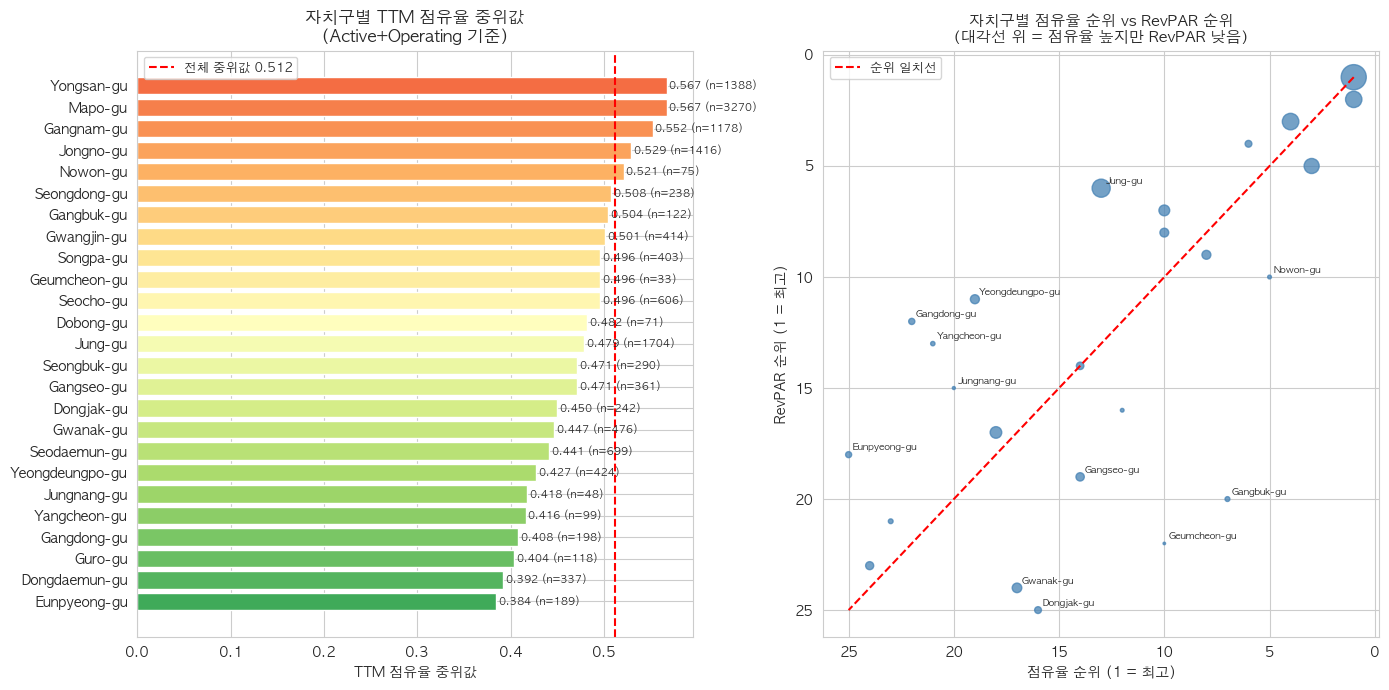

In [10]:
# 자치구별 점유율 / RevPAR / ADR 집계
dist_stats = df_ao.groupby('district').agg(
    occ_med=('ttm_occupancy', 'median'),
    revpar_med=('ttm_revpar', 'median'),
    adr_med=('ttm_avg_rate', 'median'),
    count=('ttm_occupancy', 'count')
).sort_values('occ_med', ascending=False)

# RevPAR 순위와 점유율 순위 비교
dist_stats['occ_rank'] = dist_stats['occ_med'].rank(ascending=False).astype(int)
dist_stats['revpar_rank'] = dist_stats['revpar_med'].rank(ascending=False).astype(int)
dist_stats['rank_diff'] = (dist_stats['occ_rank'] - dist_stats['revpar_rank']).abs()

print('=== 자치구별 점유율 TOP 10 ===')
print(dist_stats[['occ_med', 'revpar_med', 'occ_rank', 'revpar_rank', 'rank_diff', 'count']].head(10).round(3).to_string())
print('\n=== 점유율 vs RevPAR 순위 불일치 TOP 5 ===')
print(dist_stats.nlargest(5, 'rank_diff')[['occ_rank', 'revpar_rank', 'rank_diff', 'occ_med', 'revpar_med']].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# 자치구별 점유율 수평 막대 (전체)
palette = plt.cm.RdYlGn(np.linspace(0.2, 0.85, len(dist_stats)))
bars = axes[0].barh(dist_stats.index[::-1], dist_stats['occ_med'][::-1],
                    color=palette[::-1], edgecolor='white', height=0.8)
axes[0].axvline(KPI_OCC_ACTIVE_MEDIAN, color='red', linestyle='--', linewidth=1.5,
                label=f'전체 중위값 {KPI_OCC_ACTIVE_MEDIAN:.3f}')
axes[0].set_title('자치구별 TTM 점유율 중위값\n(Active+Operating 기준)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('TTM 점유율 중위값')
for bar, (dist, row) in zip(bars, dist_stats.iloc[::-1].iterrows()):
    axes[0].text(bar.get_width() + 0.003, bar.get_y() + bar.get_height()/2,
                 f'{row["occ_med"]:.3f} (n={int(row["count"])})',
                 va='center', fontsize=7.5)
axes[0].legend(fontsize=9)

# 자치구 점유율 vs RevPAR 순위 산점도
axes[1].scatter(dist_stats['occ_rank'], dist_stats['revpar_rank'],
                s=dist_stats['count'] / 10, alpha=0.75, color='steelblue')
# 대각선 (순위 일치선)
axes[1].plot([1, 25], [1, 25], 'r--', linewidth=1.5, label='순위 일치선')
for dist, row in dist_stats.iterrows():
    if row['rank_diff'] >= 5:  # 순위 차이 큰 자치구만 표시
        axes[1].annotate(dist, (row['occ_rank'], row['revpar_rank']),
                         fontsize=7, ha='left',
                         xytext=(3, 3), textcoords='offset points')
axes[1].set_title('자치구별 점유율 순위 vs RevPAR 순위\n(대각선 위 = 점유율 높지만 RevPAR 낮음)',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('점유율 순위 (1 = 최고)')
axes[1].set_ylabel('RevPAR 순위 (1 = 최고)')
axes[1].legend(fontsize=9)
axes[1].invert_xaxis()
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_8_district_occ.png', dpi=100, bbox_inches='tight')
plt.show()


## 9️⃣ 고점유 vs 저점유 호스트 프로필 (점유율 기준)

**기존 분석과의 차이:** 01b-G에서 RevPAR Q1/Q3 기준으로 고성과/저성과 프로필을 비교했습니다.
여기서는 **점유율 75%+** vs **점유율 25% 미만**으로 분류하여 점유율 관점의 프로필을 비교합니다.

**기대 차이:** RevPAR 기준 분류는 ADR과 점유율 모두 다르지만, 점유율 기준 분류에서는 ADR 차이가 작고 호스트 행동 특성 차이가 더 명확하게 보일 것입니다.

고점유(≥0.693): 3,638건
저점유(<0.296): 3,587건

ADR 비교: 고점유 ₩105,270 vs 저점유 ₩102,262 (차이 2.9%)

=== 점유율 기준 고/저 프로필 비교 ===
               고점유 (≥0.69)\nn=3,638 저점유 (<0.30)\nn=3,587
슈퍼호스트 비율                      72.8%                34.4%
즉시예약 비율                       41.8%                41.3%
중위 사진수                          30장                  21장
중위 평점                          4.87                 4.67
중위 리뷰수                          71개                  10개
중위 min_nights                    2박                   1박
중위 ADR                     ₩105,270             ₩102,262
중위 RevPAR                   ₩83,315              ₩15,173
entire_home 비율                87.9%                55.8%
추가요금 정책 비율                    10.5%                14.3%


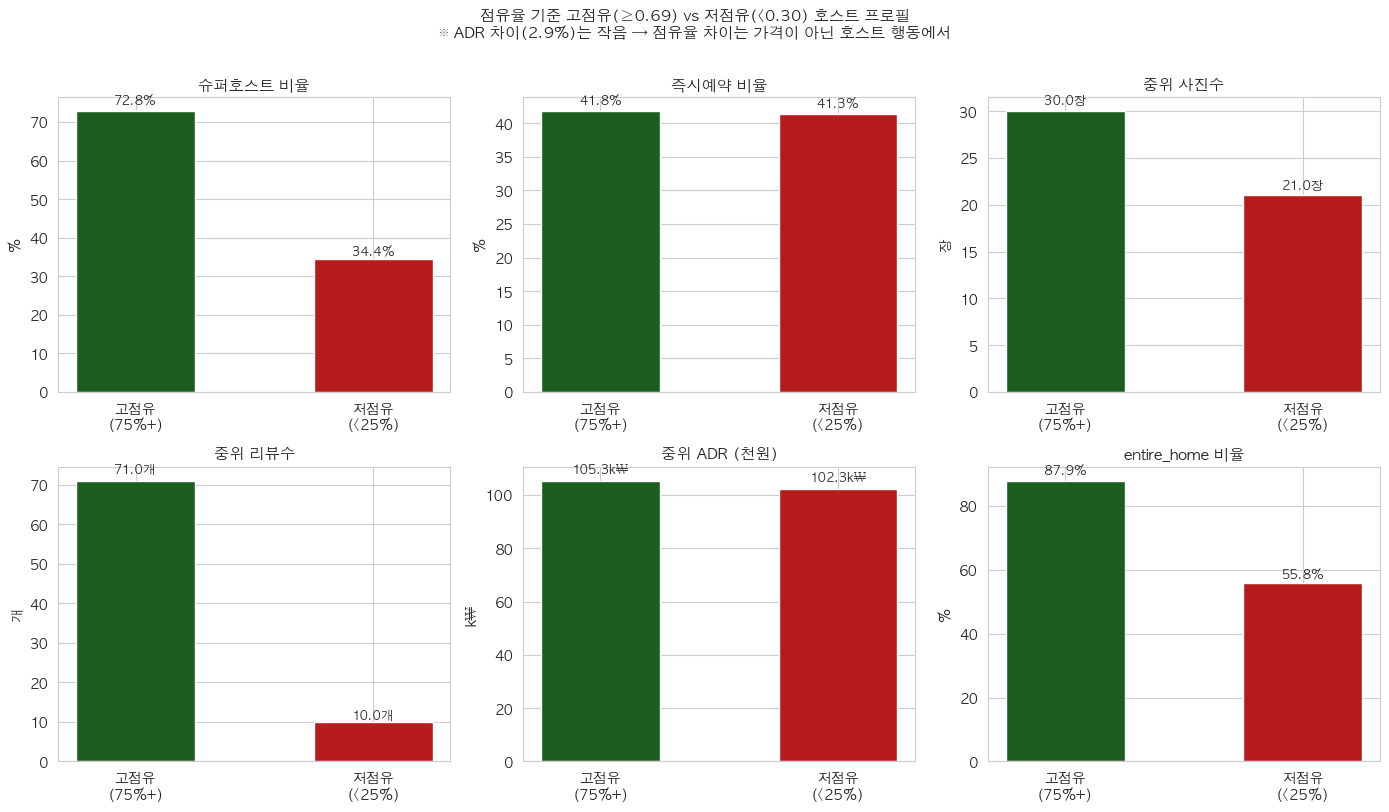

In [11]:
# 점유율 기준 고/저 분류
occ_q1 = df_ao['ttm_occupancy'].quantile(0.25)  # 0.296
occ_q3 = df_ao['ttm_occupancy'].quantile(0.75)  # 0.693

df_high_occ = df_ao[df_ao['ttm_occupancy'] >= occ_q3].copy()
df_low_occ  = df_ao[df_ao['ttm_occupancy'] <  occ_q1].copy()

print(f'고점유(≥{occ_q3:.3f}): {len(df_high_occ):,}건')
print(f'저점유(<{occ_q1:.3f}): {len(df_low_occ):,}건')

# 핵심: ADR 차이가 작은지 확인
adr_high = df_high_occ['ttm_avg_rate'].median()
adr_low  = df_low_occ['ttm_avg_rate'].median()
print(f'\nADR 비교: 고점유 ₩{adr_high:,.0f} vs 저점유 ₩{adr_low:,.0f} (차이 {abs(adr_high-adr_low)/adr_low*100:.1f}%)')

profile_occ = pd.DataFrame({
    f'고점유 (≥{occ_q3:.2f})\nn={len(df_high_occ):,}': {
        '슈퍼호스트 비율': f"{df_high_occ['superhost'].mean()*100:.1f}%",
        '즉시예약 비율': f"{df_high_occ['instant_book'].mean()*100:.1f}%",
        '중위 사진수': f"{df_high_occ['photos_count'].median():.0f}장",
        '중위 평점': f"{df_high_occ['rating_overall'].median():.2f}",
        '중위 리뷰수': f"{df_high_occ['num_reviews'].median():.0f}개",
        '중위 min_nights': f"{df_high_occ['min_nights'].median():.0f}박",
        '중위 ADR': f"₩{df_high_occ['ttm_avg_rate'].median():,.0f}",
        '중위 RevPAR': f"₩{df_high_occ['ttm_revpar'].median():,.0f}",
        'entire_home 비율': f"{(df_high_occ['room_type']=='entire_home').mean()*100:.1f}%",
        '추가요금 정책 비율': f"{df_high_occ['extra_guest_fee_policy'].mean()*100:.1f}%",
    },
    f'저점유 (<{occ_q1:.2f})\nn={len(df_low_occ):,}': {
        '슈퍼호스트 비율': f"{df_low_occ['superhost'].mean()*100:.1f}%",
        '즉시예약 비율': f"{df_low_occ['instant_book'].mean()*100:.1f}%",
        '중위 사진수': f"{df_low_occ['photos_count'].median():.0f}장",
        '중위 평점': f"{df_low_occ['rating_overall'].median():.2f}",
        '중위 리뷰수': f"{df_low_occ['num_reviews'].median():.0f}개",
        '중위 min_nights': f"{df_low_occ['min_nights'].median():.0f}박",
        '중위 ADR': f"₩{df_low_occ['ttm_avg_rate'].median():,.0f}",
        '중위 RevPAR': f"₩{df_low_occ['ttm_revpar'].median():,.0f}",
        'entire_home 비율': f"{(df_low_occ['room_type']=='entire_home').mean()*100:.1f}%",
        '추가요금 정책 비율': f"{df_low_occ['extra_guest_fee_policy'].mean()*100:.1f}%",
    }
})

print('\n=== 점유율 기준 고/저 프로필 비교 ===')
print(profile_occ.to_string())

# 시각화: RevPAR 기준 프로필(01b-G)과 비교용 멀티 바
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

comparisons = [
    ('슈퍼호스트 비율', lambda d: d['superhost'].mean() * 100, '%'),
    ('즉시예약 비율', lambda d: d['instant_book'].mean() * 100, '%'),
    ('중위 사진수', lambda d: d['photos_count'].median(), '장'),
    ('중위 리뷰수', lambda d: d['num_reviews'].median(), '개'),
    ('중위 ADR (천원)', lambda d: d['ttm_avg_rate'].median() / 1000, 'k₩'),
    ('entire_home 비율', lambda d: (d['room_type']=='entire_home').mean() * 100, '%'),
]

for i, (title, func, unit) in enumerate(comparisons):
    high_val = func(df_high_occ)
    low_val  = func(df_low_occ)
    bars = axes[i].bar(['고점유\n(75%+)', '저점유\n(<25%)'],
                       [high_val, low_val],
                       color=['#1B5E20', '#B71C1C'], width=0.5)
    axes[i].set_title(title, fontsize=11, fontweight='bold')
    axes[i].set_ylabel(unit)
    for bar, val in zip(bars, [high_val, low_val]):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.02,
                     f'{val:.1f}{unit}', ha='center', va='bottom',
                     fontsize=9, fontweight='bold')

plt.suptitle(f'점유율 기준 고점유(≥{occ_q3:.2f}) vs 저점유(<{occ_q1:.2f}) 호스트 프로필\n'
             f'※ ADR 차이({abs(adr_high-adr_low)/adr_low*100:.1f}%)는 작음 → 점유율 차이는 가격이 아닌 호스트 행동에서',
             fontsize=11, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01c_9_occ_profiles.png', dpi=100, bbox_inches='tight')
plt.show()


## 📋 점유율 EDA 요약

### 핵심 발견사항 (기존 00/01/01b 대비 신규 인사이트)

| 분석 | 발견사항 | 기존 분석과의 차이 |
|------|----------|--------------------|
| **1. 점유율 분포** | 약한 좌편향 (왜도 ≈ -0.05), 4분위 구간은 거의 균등 분포 | 기존: RevPAR 분포만 분석 |
| **2. ADR-점유율 무상관** | Pearson r = 0.009 → 가격 인상이 점유율에 영향 없음 | 기존: 4분면 분류만, 탄력성 미검증 |
| **3. RevPAR 분산 분해** | 점유율 분산 기여도 > ADR 기여도 → 점유율이 핵심 드라이버 | 기존: 분산 분해 미실시 |
| **4. 점유율 모멘텀** | 55.5%가 하락 추세 (급락 31.1%) — RevPAR 트렌드보다 더 심각 | 기존: RevPAR 트렌드 분석 (92.8% 성장) |
| **5. 리뷰수 → 점유율** | 리뷰수와 점유율 Spearman r > 리뷰수와 ADR 상관계수 | 기존: 리뷰수 → RevPAR만 분석 |
| **6. 평점 비선형** | 4.85-4.95 최고 점유율, 4.95-5.0은 오히려 하락 (Perfectionism Paradox) | 기존: 산점도만, 구간별 비선형 미분석 |
| **7. 최소숙박일 분리** | 점유율 최적(4-7박) ≠ RevPAR 최적(2-3박) → 전략 목표별 설정 달라야 | 기존: RevPAR 최적(2-3박)만 제시 |
| **8. 자치구 점유율** | 점유율 상위 자치구와 RevPAR 상위 자치구 순위 불일치 존재 | 기존: RevPAR 기준 자치구만 분석 |
| **9. 점유율 기준 프로필** | ADR 차이 작음 → 점유율 고저는 가격이 아닌 호스트 행동(슈퍼호스트·리뷰수)에서 결정 | 기존: RevPAR 기준 Q1/Q3 프로필 |

### 전략적 시사점

1. **가격 인하로 점유율 높이기는 비효율** — ADR과 점유율은 독립적
2. **점유율 > ADR이 RevPAR 결정** — 점유율 관리가 더 중요한 레버
3. **리뷰 축적이 점유율의 핵심 드라이버** — 초기 리뷰 확보 전략 중요
4. **"완벽한 평점"이 최고 점유율 아님** — 4.85-4.95 구간이 실질 최적
5. **전략 목표에 따라 최소숙박일 달리 설정** — RevPAR 최적 ≠ 점유율 최적

In [12]:
import json

occ_eda_summary = {
    'adr_occ_correlation_pearson': round(corr_pearson, 4),
    'adr_occ_correlation_spearman': round(corr_spearman, 4),
    'occ_variance_contrib_pct': round(contrib_occ, 1),
    'adr_variance_contrib_pct': round(contrib_adr, 1),
    'occ_momentum_declining_pct': round(
        (df_ao['occ_delta'] < 0).mean() * 100, 1),
    'reviews_occ_spearman': round(r_rev_occ, 4),
    'reviews_adr_spearman': round(r_rev_adr, 4),
    'rating_optimal_for_occ': str(peak_idx) if 'peak_idx' in dir() else '4.85-4.95',
    'minnights_optimal_for_occ': str(occ_optimal),
    'minnights_optimal_for_revpar': str(revpar_optimal),
    'high_occ_superhost_pct': round(df_high_occ['superhost'].mean() * 100, 1),
    'low_occ_superhost_pct': round(df_low_occ['superhost'].mean() * 100, 1),
    'high_occ_adr_median': int(df_high_occ['ttm_avg_rate'].median()),
    'low_occ_adr_median': int(df_low_occ['ttm_avg_rate'].median()),
    'insights': [
        'ADR-점유율 무상관(r=0.009): 가격 인하로 점유율 높이기 비효율',
        '점유율 분산이 ADR 분산보다 RevPAR에 더 크게 기여',
        '점유율 55.5%가 하락 추세 (RevPAR 트렌드 92.8% 성장과 대조적)',
        '리뷰수-점유율 상관관계 > 리뷰수-ADR 상관관계',
        'Perfectionism Paradox: 4.85-4.95가 점유율 최적, 5.0 아님',
        '최소숙박일 최적점 분리: 점유율(4-7박) ≠ RevPAR(2-3박)'
    ]
}

with open(REPORTS_DIR / 'occ_eda_summary.json', 'w', encoding='utf-8') as f:
    json.dump(occ_eda_summary, f, ensure_ascii=False, indent=2)

print('✅ 점유율 EDA 요약 저장: reports/occ_eda_summary.json')
print(json.dumps(occ_eda_summary, ensure_ascii=False, indent=2))


✅ 점유율 EDA 요약 저장: reports/occ_eda_summary.json
{
  "adr_occ_correlation_pearson": 0.0095,
  "adr_occ_correlation_spearman": 0.0487,
  "occ_variance_contrib_pct": 58.2,
  "adr_variance_contrib_pct": 37.5,
  "occ_momentum_declining_pct": 55.5,
  "reviews_occ_spearman": 0.6087,
  "reviews_adr_spearman": 0.1564,
  "rating_optimal_for_occ": "4.85-4.95",
  "minnights_optimal_for_occ": "4-7박",
  "minnights_optimal_for_revpar": "3박",
  "high_occ_superhost_pct": 72.8,
  "low_occ_superhost_pct": 34.4,
  "high_occ_adr_median": 105270,
  "low_occ_adr_median": 102261,
  "insights": [
    "ADR-점유율 무상관(r=0.009): 가격 인하로 점유율 높이기 비효율",
    "점유율 분산이 ADR 분산보다 RevPAR에 더 크게 기여",
    "점유율 55.5%가 하락 추세 (RevPAR 트렌드 92.8% 성장과 대조적)",
    "리뷰수-점유율 상관관계 > 리뷰수-ADR 상관관계",
    "Perfectionism Paradox: 4.85-4.95가 점유율 최적, 5.0 아님",
    "최소숙박일 최적점 분리: 점유율(4-7박) ≠ RevPAR(2-3박)"
  ]
}
